# Étape 9 : étage 2, allocation et backtest

À partir des z-scores de l'étape 8 :
1. on calcule un **score final** par action et par mois, en combinant les z-scores des facteurs de deux façons (équipondération, ERC) ;
2. on construit un portefeuille **long-only** : les actions au meilleur score, pondérées par capitalisation × (1 + score) ;
3. on le **backteste** avec des frais de transaction, face au S&P 500, et on teste statistiquement l'écart.

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

## 1. Les données

- z-scores mensuels de l'étape 8 (membres du S&P 500, février 2012 à août 2026) ;
- rendements mensuels des actions, dividendes compris ;
- facteurs de Fama et French (pour le taux sans risque, l'ERC et l'analyse des expositions) ;
- SPY (ETF S&P 500) et RSP (ETF S&P 500 équipondéré), dividendes compris.

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


## 2. Long-only, et quels facteurs

**Long-only.** C'est le choix qui découle des étapes précédentes :
- l'univers est le S&P 500, choisi pour être investissable (étape 8) ;
- la version long-only est celle des fonds multi-facteurs comme ceux d'Amundi (étape 7.3) ;
- pas de vente à découvert, donc pas de coût d'emprunt de titres ni de risque de remontée brutale d'une action vendue.

Le portefeuille reste donc exposé au marché (bêta proche de 1). Les facteurs servent à **choisir et pondérer les actions** à l'intérieur du S&P 500.

**Cinq facteurs dans le score : SMB, HML, RMW, CMA, Mom.** Le z-score de marché (`z_mkt`, le bêta) n'entre pas dans le score : un portefeuille long-only est déjà exposé au marché, et favoriser les actions à bêta élevé n'a pas été rémunéré (Frazzini et Pedersen, 2014).

In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

## 3. Le score final

Pour chaque action $i$ et chaque mois $t$ :

$$S_{i,t} = \sum_k w_{k,t}\, z_{i,k,t}, \qquad \sum_k w_{k,t} = 1$$

puis on re-standardise $S$ sur les actions du mois (moyenne 0, écart-type 1), pour que les deux méthodes soient sur la même échelle.

- **Équipondéré** : $w_k = 1/5$ pour chaque facteur.
- **ERC** : les poids $w_{k,t}$ donnent à chaque facteur la même contribution au risque, calculée sur les rendements des facteurs de Fama et French des **60 mois précédents** (de $t-59$ à $t$). Un facteur très volatil reçoit un poids plus faible.

Données manquantes : une action doit avoir au moins 3 des 5 z-scores ; un z-score manquant vaut 0 (neutre).

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


## 4. Du score au portefeuille

Chaque fin de mois $t$ :

1. **Sélection** : les 30 % d'actions au meilleur score.
2. **Zone tampon** : une action déjà en portefeuille n'est vendue que si elle sort des 40 % meilleurs. Cela évite de vendre puis racheter une action dont le score bouge à peine autour du seuil.
3. **Pondération** : $w_i \propto \text{capitalisation}_i \times (1 + S_i)$. On part du poids naturel de l'action dans l'indice, augmenté selon son score.
4. **Plafond de 10 % par action**, comme la règle de diversification des fonds européens (OPCVM). Sans lui, Apple, très grosse et bien notée en 2020, aurait pesé jusqu'à 37 % du portefeuille.
5. Le portefeuille est détenu pendant le mois $t+1$.

Les deux autres pondérations (égale, capitalisation seule) sont testées en robustesse.

In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

## 5. Le backtest et les frais

- Rendement du mois $t+1$ : $\sum_i w_{i,t}\, r_{i,t+1}$, dividendes compris.
- Entre deux rééquilibrages, les poids **dérivent** avec les cours. La rotation est l'écart entre ces poids dérivés et les nouveaux poids cibles : $\text{rotation}_t = \sum_i |w^{\text{cible}}_{i,t} - w^{\text{dérivé}}_{i,t}|$ (achats + ventes).
- **Frais** : 10 points de base (0,10 %) par dollar échangé, retirés du rendement : $r^{\text{net}} = r^{\text{brut}} - 0{,}001 \times \text{rotation}$. C'est un ordre de grandeur réaliste pour des grandes capitalisations américaines (écart achat-vente et impact de marché). Sensibilité de 0 à 50 points de base plus bas.
- Une action sans cours le mois suivant est comptée à 0 % de rendement (cas qui ne se produit pas ici, voir la sortie).

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}


strategies = {
    "Score équipondéré": backtest(poids_cibles(scores["score_equipondere"])),
    "Score ERC": backtest(poids_cibles(scores["score_erc"])),
}
reference = backtest(univers_capi())
periode = reference.index
print(f"Backtest : {periode[0]} à {periode[-1]}, {len(periode)} mois")
print("Rendements manquants pour des actions détenues :", {k: v.attrs["manquants"] for k, v in strategies.items()})
for nom, col in [("Score équipondéré", "score_equipondere"), ("Score ERC", "score_erc")]:
    c = poids_cibles(scores[col])
    n = pd.Series({m: len(w) for m, w in c.items()})
    top10 = pd.Series({m: w.nlargest(10).sum() for m, w in c.items()})
    print(f"{nom} : {n.mean():.0f} actions en moyenne ({n.min()} à {n.max()}), "
          f"poids des 10 premières lignes {top10.mean():.0%} en moyenne")

Backtest : 2012-03 à 2026-08, 174 mois
Rendements manquants pour des actions détenues : {'Score équipondéré': 0, 'Score ERC': 0}


Score équipondéré : 141 actions en moyenne (97 à 170), poids des 10 premières lignes 29% en moyenne


Score ERC : 142 actions en moyenne (97 à 172), poids des 10 premières lignes 36% en moyenne


## 6. Les benchmarks

- **Univers pondéré par la capitalisation** : toutes les actions de la base, au poids de l'indice. C'est le benchmark principal : mêmes actions, mêmes données. La seule différence avec les stratégies est le choix et la pondération par les facteurs.
- **SPY** : ce qu'un investisseur aurait vraiment obtenu en achetant le S&P 500 et en le gardant.
- **RSP** : le S&P 500 équipondéré, pour voir l'effet d'un simple éloignement des poids de l'indice.

In [8]:
def indicateurs(r):
    r = r.reindex(periode)
    exces = r - rf.reindex(periode)
    valeur = (1 + r).cumprod()
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
    })


series = {k: v["net"] for k, v in strategies.items()}
series["Univers (capitalisation)"] = reference["net"]
series["SPY"] = rend_etf["SPY"]
series["RSP"] = rend_etf["RSP"]
resultats = pd.DataFrame({k: indicateurs(v) for k, v in series.items()}).T
resultats["rotation annuelle"] = [strategies[k]["rotation"].iloc[1:].mean() * 12 if k in strategies else
                                  (reference["rotation"].iloc[1:].mean() * 12 if k.startswith("Univers") else np.nan)
                                  for k in resultats.index]
resultats["frais annuels"] = [strategies[k]["rotation"].iloc[1:].mean() * 12 * 0.001 if k in strategies else np.nan
                              for k in resultats.index]
resultats.style.format({"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                        "perte maximale": "{:.1%}", "rotation annuelle": "{:.0%}", "frais annuels": "{:.2%}"}, na_rep="")

,rendement annuel,volatilité,Sharpe,perte maximale,rotation annuelle,frais annuels
Score équipondéré,15.6%,15.8%,0.90,-28.2%,315%,0.31%
Score ERC,14.7%,15.4%,0.87,-23.2%,278%,0.28%
Univers (capitalisation),15.1%,14.0%,0.96,-23.6%,11%,
SPY,14.6%,14.0%,0.93,-23.9%,,
RSP,12.5%,15.1%,0.75,-26.7%,,


## 7. L'écart avec le benchmark est-il significatif ?

Pour chaque stratégie, on regarde le **rendement actif** $a_t = r^{\text{stratégie}}_t - r^{\text{benchmark}}_t$, net de frais.

- **Test de la moyenne** : $t$ de Student avec des erreurs robustes à l'autocorrélation (Newey-West, 6 retards).
- **Ratio d'information** : $\text{IR} = \bar a / \sigma_a \times \sqrt{12}$.
- **Intervalle de confiance par bootstrap** : on rééchantillonne des blocs de mois consécutifs (bootstrap stationnaire, blocs de 6 mois en moyenne, 5 000 tirages), en gardant ensemble les mois de la stratégie et du benchmark. On obtient un intervalle à 95 % pour le rendement actif et pour l'écart de Sharpe.

In [9]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])


lignes = []
for nom_bench, bench in [("Univers (capitalisation)", reference["net"]), ("SPY", rend_etf["SPY"].reindex(periode))]:
    for nom, bt in list(strategies.items()) + ([("Univers (capitalisation)", reference)] if nom_bench == "SPY" else []):
        a = bt["net"] - bench
        moy, t, p = test_moyenne(a)
        ic_actif, ic_sharpe = bootstrap(bt["net"], bench)
        lignes.append({"stratégie": nom, "benchmark": nom_bench, "rendement actif annuel": 12 * moy,
                       "écart de suivi": a.std() * np.sqrt(12), "IR": a.mean() / a.std() * np.sqrt(12),
                       "t (Newey-West)": t, "p-valeur": p,
                       "IC 95 % rendement actif": f"[{ic_actif[0]:+.1%} ; {ic_actif[1]:+.1%}]",
                       "écart de Sharpe": sharpe(bt["net"], rf.reindex(periode)) - sharpe(bench, rf.reindex(periode)),
                       "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
# Les deux scores entre eux
a = strategies["Score équipondéré"]["net"] - strategies["Score ERC"]["net"]
moy, t, p = test_moyenne(a)
ic_actif, ic_sharpe = bootstrap(strategies["Score équipondéré"]["net"], strategies["Score ERC"]["net"])
lignes.append({"stratégie": "Score équipondéré", "benchmark": "Score ERC", "rendement actif annuel": 12 * moy,
               "écart de suivi": a.std() * np.sqrt(12), "IR": a.mean() / a.std() * np.sqrt(12),
               "t (Newey-West)": t, "p-valeur": p,
               "IC 95 % rendement actif": f"[{ic_actif[0]:+.1%} ; {ic_actif[1]:+.1%}]",
               "écart de Sharpe": sharpe(strategies["Score équipondéré"]["net"], rf.reindex(periode))
               - sharpe(strategies["Score ERC"]["net"], rf.reindex(periode)),
               "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
tests = pd.DataFrame(lignes).set_index(["stratégie", "benchmark"])
tests.style.format({"rendement actif annuel": "{:+.2%}", "écart de suivi": "{:.1%}", "IR": "{:+.2f}",
                    "t (Newey-West)": "{:+.2f}", "p-valeur": "{:.2f}", "écart de Sharpe": "{:+.2f}"})

,,rendement actif annuel,écart de suivi,IR,t (Newey-West),p-valeur,IC 95 % rendement actif,écart de Sharpe,IC 95 % écart de Sharpe
stratégie,benchmark,,,,,,,,
Score équipondéré,Univers (capitalisation),+0.77%,7.2%,+0.11,+0.38,0.70,[-2.9% ; +4.5%],-0.06,[-0.32 ; +0.24]
Score ERC,Univers (capitalisation),-0.12%,6.4%,-0.02,-0.07,0.95,[-3.5% ; +3.0%],-0.10,[-0.36 ; +0.13]
Score équipondéré,SPY,+1.19%,6.9%,+0.17,+0.61,0.54,[-2.3% ; +4.8%],-0.03,[-0.29 ; +0.25]
Score ERC,SPY,+0.29%,6.2%,+0.05,+0.17,0.86,[-3.0% ; +3.3%],-0.07,[-0.33 ; +0.15]
Univers (capitalisation),SPY,+0.41%,0.8%,+0.55,+2.64,0.01,[+0.1% ; +0.7%],+0.03,[+0.00 ; +0.05]
Score équipondéré,Score ERC,+0.89%,3.8%,+0.23,+0.81,0.42,[-1.2% ; +3.1%],+0.04,[-0.11 ; +0.22]


**Quelle surperformance aurait-on pu détecter ?** Avec $T$ années de données, le $t$ du rendement actif vaut environ $\text{IR} \times \sqrt{T}$. Pour atteindre $t = 2$, il faut donc $\text{IR} \ge 2 / \sqrt{T}$.

In [10]:
annees = len(periode) / 12
print(f"{annees:.1f} ans de backtest : IR minimal détectable (t = 2) = {2 / np.sqrt(annees):.2f}")

14.5 ans de backtest : IR minimal détectable (t = 2) = 0.53


## 8. Ce que les stratégies portent vraiment : régression sur les six facteurs

On régresse le rendement excédentaire de chaque portefeuille sur les six facteurs de Fama et French (comme à l'étape 4). Les coefficients montrent si le portefeuille porte bien les expositions voulues. L'alpha est ce qui reste une fois ces expositions retirées.

In [11]:
SIX = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
X = sm.add_constant(facteurs.loc[periode, SIX])
expo = {}
for nom, r in [("Score équipondéré", strategies["Score équipondéré"]["net"]),
               ("Score ERC", strategies["Score ERC"]["net"]),
               ("Univers (capitalisation)", reference["net"])]:
    m = sm.OLS(r - rf.reindex(periode), X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    ligne = m.params.rename({"const": "alpha annuel"})
    ligne["alpha annuel"] *= 12
    ligne["t alpha"] = m.tvalues["const"]
    ligne["R²"] = m.rsquared
    expo[nom] = ligne
expositions = pd.DataFrame(expo).T
expositions.style.format("{:.2f}").format("{:+.1%}", subset=["alpha annuel"])

,alpha annuel,Mkt-RF,SMB,HML,RMW,CMA,Mom,t alpha,R²
Score équipondéré,+0.4%,1.03,0.09,0.39,-0.00,0.15,0.16,0.35,0.93
Score ERC,-0.7%,1.04,0.11,0.21,0.03,0.19,0.20,-0.53,0.91
Univers (capitalisation),+0.2%,0.99,-0.12,-0.00,0.05,0.02,0.01,0.89,0.99


### Les primes des facteurs pendant le backtest

Une stratégie factorielle ne peut gagner que si les facteurs qu'elle porte sont rémunérés. Rendement annuel moyen des facteurs de Fama et French, pendant le backtest et avant :

In [12]:
def primes(debut, fin):
    f = facteurs.loc[debut:fin, SIX]
    return pd.DataFrame({"prime annuelle": 12 * f.mean(), "t": f.mean() / f.std() * np.sqrt(len(f))})


comparaison_primes = pd.concat({f"1963-2011": primes("1963-07", "2011-12"),
                                f"{periode[0]} à {periode[-1]}": primes(periode[0], periode[-1])}, axis=1)
comparaison_primes.style.format("{:.2f}").format("{:.1%}", subset=[c for c in comparaison_primes.columns if c[1] == "prime annuelle"])

## 9. Robustesse

### Sous-périodes

In [13]:
sous_periodes = {"2012-2019": ("2012-03", "2019-12"), "2020-2026": ("2020-01", "2026-08")}
lignes = []
for nom, bt in strategies.items():
    for sp, (d, f) in sous_periodes.items():
        a = (bt["net"] - reference["net"]).loc[d:f]
        moy, t, p = test_moyenne(a)
        lignes.append({"stratégie": nom, "période": sp, "rendement actif annuel": 12 * moy,
                       "IR": a.mean() / a.std() * np.sqrt(12), "t (Newey-West)": t})
pd.DataFrame(lignes).set_index(["stratégie", "période"]).style.format(
    {"rendement actif annuel": "{:+.2%}", "IR": "{:+.2f}", "t (Newey-West)": "{:+.2f}"})

### Pondération, seuil et zone tampon

Toutes les variantes, contre l'univers pondéré par la capitalisation, avec 10 points de base de frais.

In [14]:
variantes = []
for nom_score, col in [("équipondéré", "score_equipondere"), ("ERC", "score_erc")]:
    for ponderation, libelle in [("egale", "égale"), ("capi", "capitalisation"),
                                 ("capi_score", "capitalisation × (1 + score)")]:
        for seuil, tampon in [(0.30, None), (0.30, 0.40), (0.30, 0.50), (0.20, 0.30), (0.50, 0.60)]:
            bt = backtest(poids_cibles(scores[col], seuil, tampon, ponderation))
            a = bt["net"] - reference["net"]
            variantes.append({"score": nom_score, "pondération": libelle,
                              "seuil / tampon": f"{seuil:.0%} / {tampon:.0%}" if tampon else f"{seuil:.0%} / aucun",
                              "rendement actif annuel": 12 * a.mean(), "IR": a.mean() / a.std() * np.sqrt(12),
                              "t (Newey-West)": test_moyenne(a)[1], "rotation annuelle": bt["rotation"].iloc[1:].mean() * 12,
                              "_actif": a})
variantes = pd.DataFrame(variantes)
tableau = variantes.drop(columns="_actif").set_index(["score", "pondération", "seuil / tampon"])
tableau.style.format({"rendement actif annuel": "{:+.2%}", "IR": "{:+.2f}", "t (Newey-West)": "{:+.2f}",
                      "rotation annuelle": "{:.0%}"})

### Le meilleur résultat n'est-il pas dû au hasard ?

On a testé 30 variantes. La meilleure aura forcément un bon résultat, même si aucune ne fonctionne vraiment. Le **ratio de Sharpe dégonflé** (Bailey et López de Prado, 2014) corrige ce biais. Il donne la probabilité que le vrai ratio d'information de la meilleure variante soit positif, compte tenu :
- du nombre de variantes essayées et de la dispersion de leurs résultats ;
- de la longueur du backtest, de l'asymétrie et des queues épaisses des rendements.

In [15]:
ir_mensuels = variantes["_actif"].apply(lambda a: a.mean() / a.std())
meilleure = variantes.loc[ir_mensuels.idxmax()]
a = meilleure["_actif"]
n_essais, T = len(variantes), len(a)
gamma = 0.5772156649
seuil_sr = np.sqrt(ir_mensuels.var()) * ((1 - gamma) * norm.ppf(1 - 1 / n_essais)
                                         + gamma * norm.ppf(1 - 1 / (n_essais * np.e)))
sr = a.mean() / a.std()
asym, kurt = a.skew(), a.kurt() + 3
dsr = norm.cdf((sr - seuil_sr) * np.sqrt(T - 1) / np.sqrt(1 - asym * sr + (kurt - 1) / 4 * sr ** 2))
psr = norm.cdf(sr * np.sqrt(T - 1) / np.sqrt(1 - asym * sr + (kurt - 1) / 4 * sr ** 2))
print(f"Meilleure variante : score {meilleure['score']}, pondération {meilleure['pondération']}, "
      f"seuil / tampon {meilleure['seuil / tampon']}")
print(f"IR annualisé : {sr * np.sqrt(12):.2f}")
print(f"Probabilité que l'IR soit positif, sans correction : {psr:.0%}")
print(f"Après correction pour {n_essais} essais (ratio de Sharpe dégonflé) : {dsr:.0%}")

Meilleure variante : score équipondéré, pondération capitalisation × (1 + score), seuil / tampon 30% / 40%
IR annualisé : 0.11
Probabilité que l'IR soit positif, sans correction : 66%
Après correction pour 30 essais (ratio de Sharpe dégonflé) : 38%


### Frais de transaction

In [16]:
niveaux = [0, 5, 10, 25, 50]
sensibilite = pd.DataFrame({
    nom: [12 * (bt["brut"] - pb / 1e4 * bt["rotation"] - reference["brut"] + pb / 1e4 * reference["rotation"]).mean()
          for pb in niveaux]
    for nom, bt in strategies.items()}, index=pd.Index(niveaux, name="frais (points de base)"))
sensibilite.style.format("{:+.2%}")

,Score équipondéré,Score ERC
frais (points de base),,
0,+1.08%,+0.14%
5,+0.92%,+0.01%
10,+0.77%,-0.12%
25,+0.32%,-0.52%
50,-0.44%,-1.18%


## 10. Graphiques

In [17]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

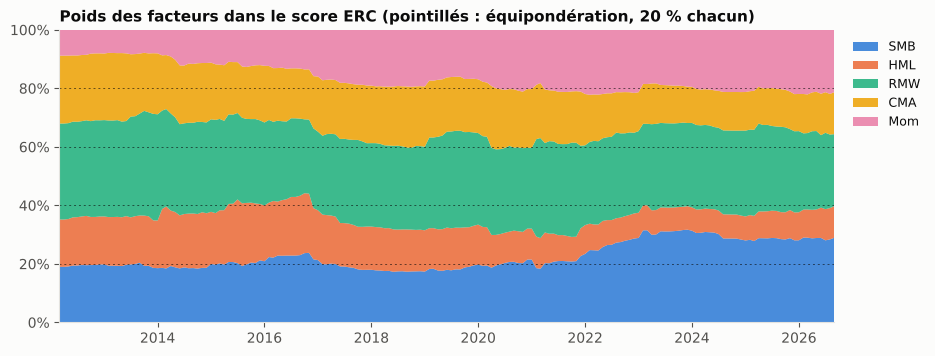

In [18]:
# Poids ERC des facteurs dans le score
fig, ax = plt.subplots(figsize=(10, 3.8))
d = poids.index.to_timestamp(how="end")
couleurs_f = [BLEU, ORANGE, AQUA, JAUNE, MAGENTA]
ax.stackplot(d, poids.T.values, colors=couleurs_f, alpha=0.85, lw=0, labels=poids.columns)
ax.axhline(0.2, color=SURFACE, lw=0)
for k in range(1, 5):
    ax.axhline(0.2 * k, color=TEXTE, lw=0.7, ls=(0, (2, 3)), alpha=0.6)
ax.set_ylim(0, 1)
ax.set_xlim(d[0], d[-1])
ax.yaxis.set_major_formatter(virgule("{:.0%}"))
ax.set_title("Poids des facteurs dans le score ERC (pointillés : équipondération, 20 % chacun)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.grid(False)
sauver(fig, "allocation_poids_erc.png")
plt.show()

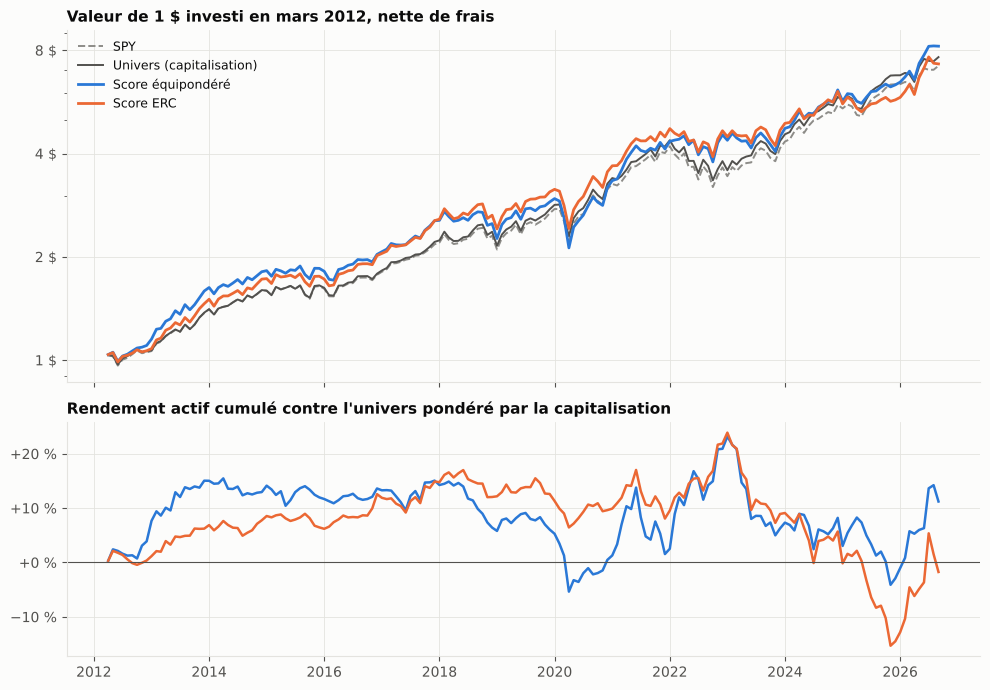

In [19]:
# Performance cumulée et rendement actif cumulé
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
d = periode.to_timestamp(how="end")
for nom in ["SPY", "Univers (capitalisation)", "Score équipondéré", "Score ERC"]:
    r = series[nom].reindex(periode)
    ax1.plot(d, (1 + r).cumprod(), color=COULEURS[nom], lw=2 if nom.startswith("Score") else 1.4,
             ls="--" if nom == "SPY" else "-", label=nom)
ax1.set_yscale("log")
ax1.set_yticks([1, 2, 4, 8])
ax1.yaxis.set_major_formatter(virgule("{:.0f} $"))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_title("Valeur de 1 $ investi en mars 2012, nette de frais")
ax1.legend(loc="upper left", fontsize=9)
for nom in ["Score équipondéré", "Score ERC"]:
    a = strategies[nom]["net"] - reference["net"]
    ax2.plot(d, 100 * a.cumsum(), color=COULEURS[nom], lw=1.8, label=nom)
ax2.axhline(0, color=TEXTE2, lw=0.8)
ax2.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax2.set_title("Rendement actif cumulé contre l'univers pondéré par la capitalisation")
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "allocation_performance.png")
plt.show()

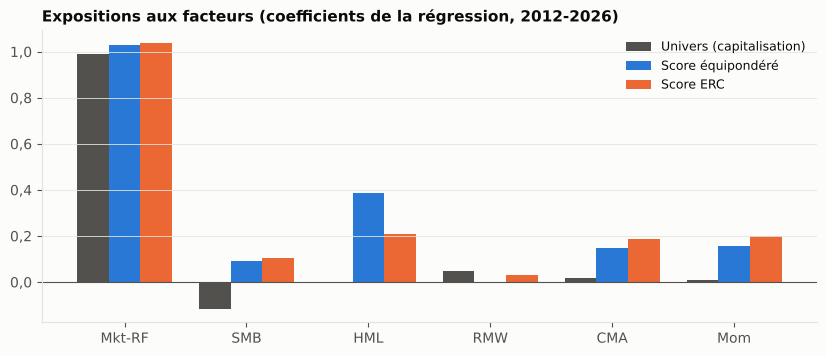

In [20]:
# Expositions aux six facteurs
fig, ax = plt.subplots(figsize=(10, 3.8))
noms = ["Univers (capitalisation)", "Score équipondéré", "Score ERC"]
x = np.arange(len(SIX))
largeur = 0.26
for j, nom in enumerate(noms):
    v = expositions.loc[nom, SIX].values.astype(float)
    ax.bar(x + (j - 1) * largeur, v, largeur, color=COULEURS[nom], label=nom)
ax.axhline(0, color=TEXTE2, lw=0.8)
ax.set_xticks(x, SIX)
ax.yaxis.set_major_formatter(virgule("{:.1f}"))
ax.set_title("Expositions aux facteurs (coefficients de la régression, 2012-2026)")
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="x", visible=False)
sauver(fig, "allocation_expositions.png")
plt.show()

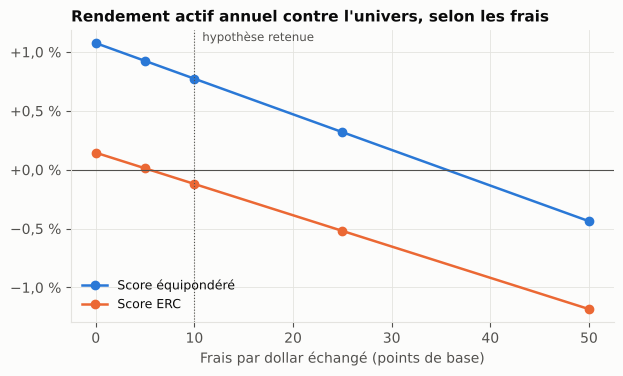

In [21]:
# Sensibilité aux frais
fig, ax = plt.subplots(figsize=(7, 3.8))
for nom in strategies:
    ax.plot(sensibilite.index, 100 * sensibilite[nom], marker="o", color=COULEURS[nom], lw=1.8, label=nom)
ax.axhline(0, color=TEXTE2, lw=0.8)
ax.axvline(10, color=TEXTE2, lw=0.8, ls=":")
ax.text(10.8, ax.get_ylim()[1] * 0.92, "hypothèse retenue", color=TEXTE2, fontsize=8.5)
ax.set_xlabel("Frais par dollar échangé (points de base)")
ax.yaxis.set_major_formatter(virgule("{:+.1f} %"))
ax.set_title("Rendement actif annuel contre l'univers, selon les frais")
ax.legend(loc="lower left", fontsize=9)
sauver(fig, "allocation_frais.png")
plt.show()